In [1]:
!pip install -U tbparse

Looking in indexes: https://pypi.python.org/simple/
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.5/5.5 MB 5.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 21.8 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: tensorboard-data-server
    Found existing installation: tensorboard-data-server 0.6.1
ERROR: Cannot uninstall tensorboard-data-server 0.6.1, RECORD file not found. You might be able to recover from this via: 'pip install --force-reinstall --no-deps tensorboard-data-server==0.6.1'.

[notice] A new release of pip is available: 24.0 -> 25.2
[notice] To update, run: pip install --upgrade pip


In [1]:
import numpy as np
from tbparse import SummaryReader
import matplotlib.pyplot as plt
import seaborn as sns
import json

In [ ]:
var = "pearo_z_500hpa"

## RMSE

In [268]:
var = ["aro_t_850hpa", "aro_t2m_2m", "aro_u10_10m", "aro_v10_10m", "aro_tp_0m", "aro_z_500hpa"]
var_name = [r'$Temp_{850hPa}$', r'$Temp_{2m}$', r'$U_{10m}$', r'$V_{10m}$', r'$Total Precip$', r'$Z_{500hPa}$']
linestyle = ['-.', '--', '-', ':', (0, (3, 1, 1, 1, 1, 1))]

In [288]:
# Read and parse the JSON file

k=0

with open("/data/titan_21var/base_0order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_0_order = data[var[k]]

with open("/data/titan_21var/base_2order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_2_order = data[var[k]]

with open("/data/titan_21var/base_1order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_1_order = data[var[k]]

with open("/data/titan_21var/base_2order_5em4_bckwrd/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_2_order_bckwrd = data[var[k]]


In [223]:
# concatenate all data for normalization
all_data = np.concatenate([df_base_0_order, df_base_1_order, df_base_2_order, df_base_2_order_bckwrd])
min_val = np.min(all_data)
max_val = np.max(all_data)
std = np.std(all_data)

In [224]:
# Read and parse the JSON file

with open("/data/titan_21var/base_0order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_0_order = data[var[k]]/std

with open("/data/titan_21var/base_2order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_2_order = data[var[k]]/std

with open("/data/titan_21var/base_1order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_1_order = data[var[k]]/std

with open("/data/titan_21var/base_2order_5em4_bckwrd/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

    df_base_2_order_bckwrd = data[var[k]]/std

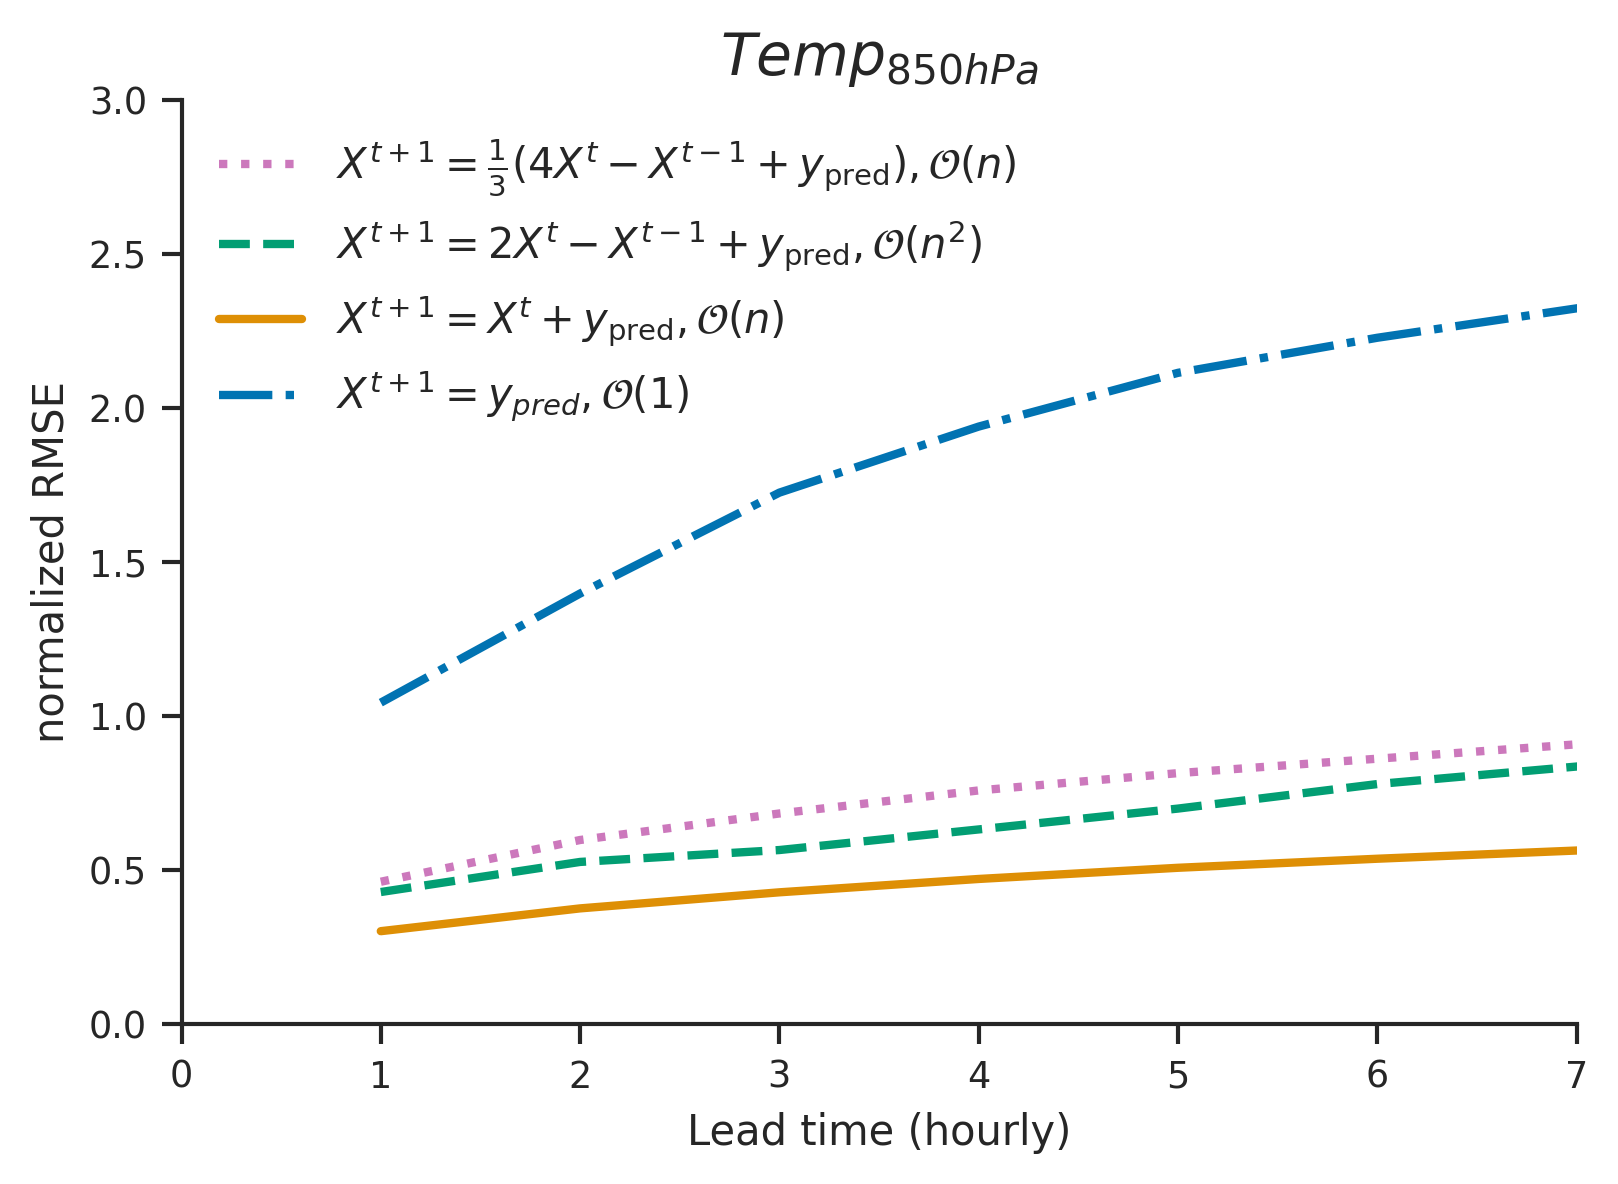

In [289]:
# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Create the figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

LTs = np.arange(1, 43, 1)

# Plot with distinct, publication-quality colors and styles

ax.plot(LTs, df_base_2_order_bckwrd, label=r'$X^{t+1} = \frac{1}{3} (4X^{t} - X^{t-1} + y_{\text{pred}}) , \mathcal{O}(n)$',
        color=palette[4], linestyle=':', linewidth=2)
ax.plot(LTs, df_base_2_order, label=r'$X^{t+1} = 2X^{t} - X^{t-1} + y_{\text{pred}}, \mathcal{O}(n^2)$',
        color=palette[2], linestyle='--', linewidth=2)
ax.plot(LTs, df_base_1_order, label=r'$X^{t+1} = X^{t} + y_{\text{pred}}, \mathcal{O}(n)$',
        color=palette[1], linestyle='-', linewidth=2)
ax.plot(LTs, df_base_0_order, label=r'$X^{t+1}=y_{pred}, \mathcal{O}(1)$',
        color=palette[0], linestyle='-.', linewidth=2)





# Labels and title with LaTeX for better typography
ax.set_title(var_name[k], fontsize=14, weight='bold')
ax.set_xlabel(r'Lead time (hourly)', fontsize=10)
ax.set_ylabel(r'normalized RMSE', fontsize=10)
ax.set_ylim(0,3)
ax.set_xlim(0,7)

# Customize legend
ax.legend(frameon=False, fontsize=10, loc='upper left')

# Remove top and right borders
sns.despine()

# Show the plot
plt.show()

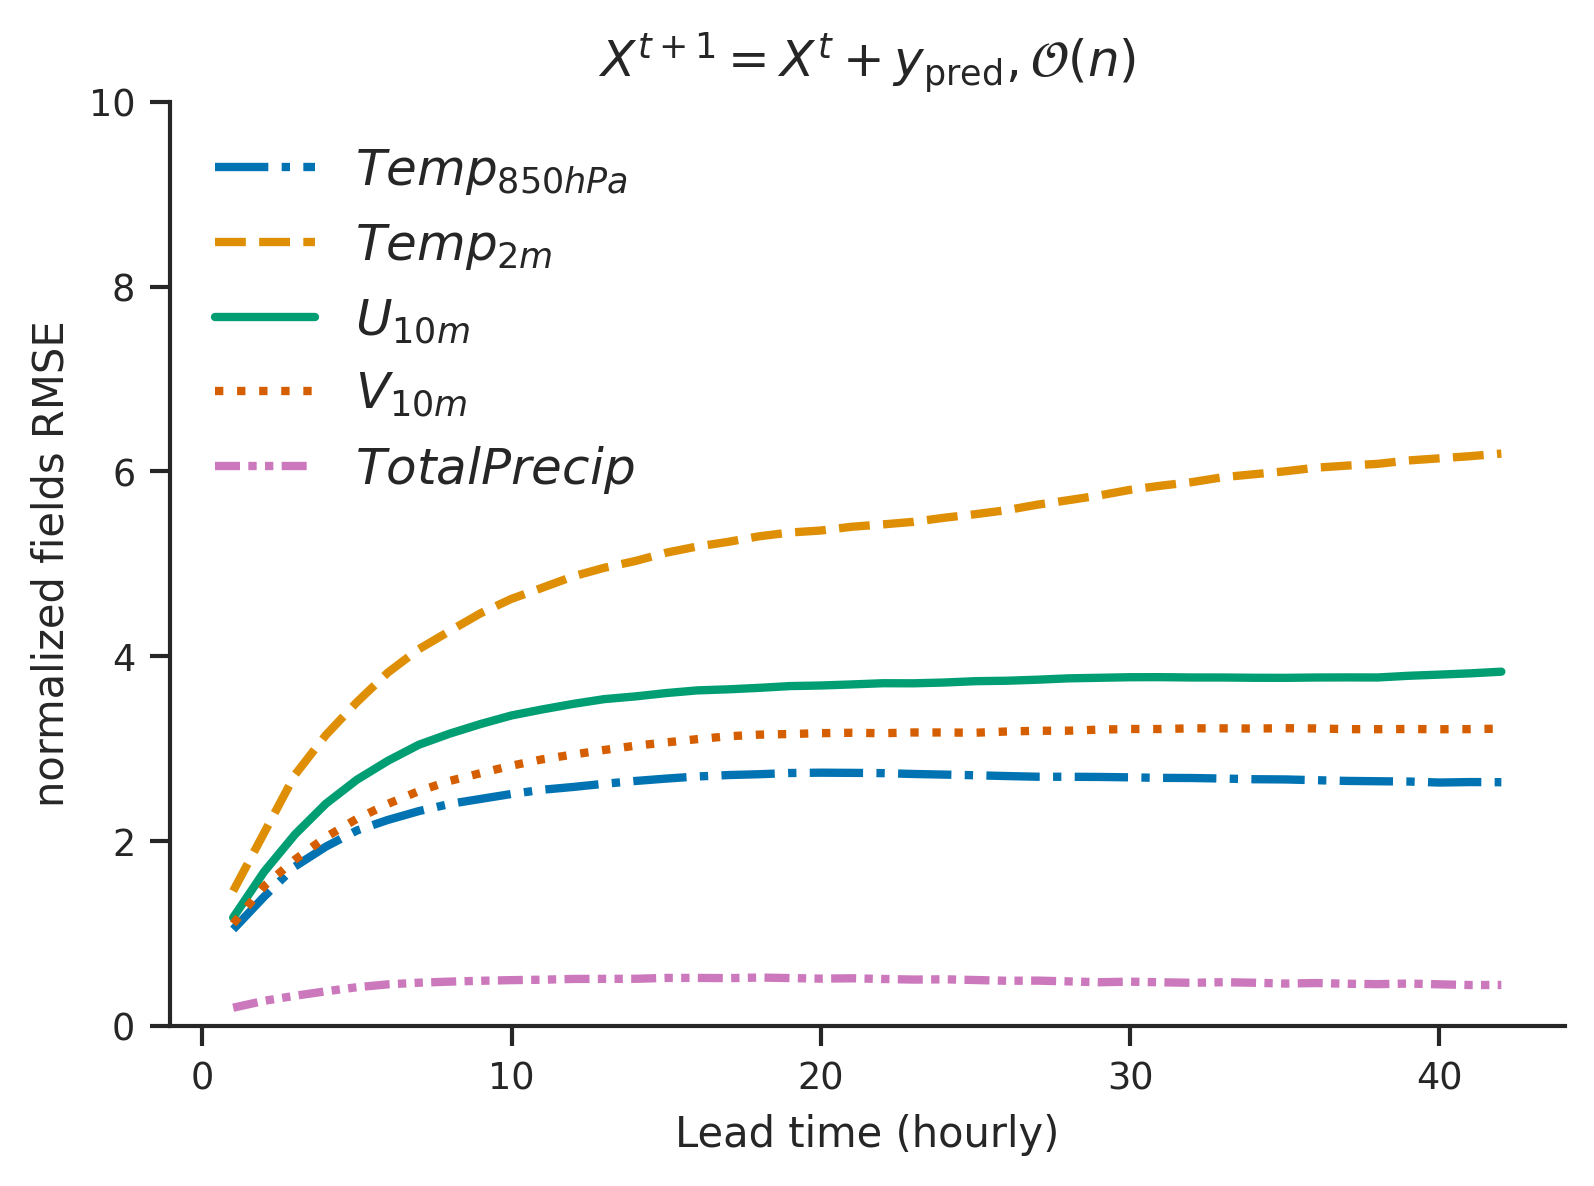

In [235]:
with open("/data/titan_21var/base_0order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Create the figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

LTs = np.arange(1, 43, 1)

# Plot with distinct, publication-quality colors and styles
var = ["aro_t_850hpa", "aro_t2m_2m", "aro_u10_10m", "aro_v10_10m", "aro_tp_0m"]
var_name = [r'$Temp_{850hPa}$', r'$Temp_{2m}$', r'$U_{10m}$', r'$V_{10m}$', r'$Total Precip$']
linestyle = ['-.', '--', '-', ':', (0, (3, 1, 1, 1, 1, 1))]

for k in range(5):

        ax.plot(LTs, data[var[k]], label=var_name[k],
                color=palette[k], linestyle=linestyle[k], linewidth=2)


# Labels and title with LaTeX for better typography
ax.set_xlabel(r'Lead time (hourly)', fontsize=10)
ax.set_ylabel(r'normalized fields RMSE', fontsize=10)
ax.set_title(r'$X^{t+1} = X^{t} + y_{\text{pred}}, \mathcal{O}(n)$', fontsize=12, weight='bold')
ax.set_ylim(0, 10)

# Customize legend
ax.legend(frameon=False, fontsize=12, loc='upper left')

# Remove top and right borders
sns.despine()

# Show the plot
plt.show()

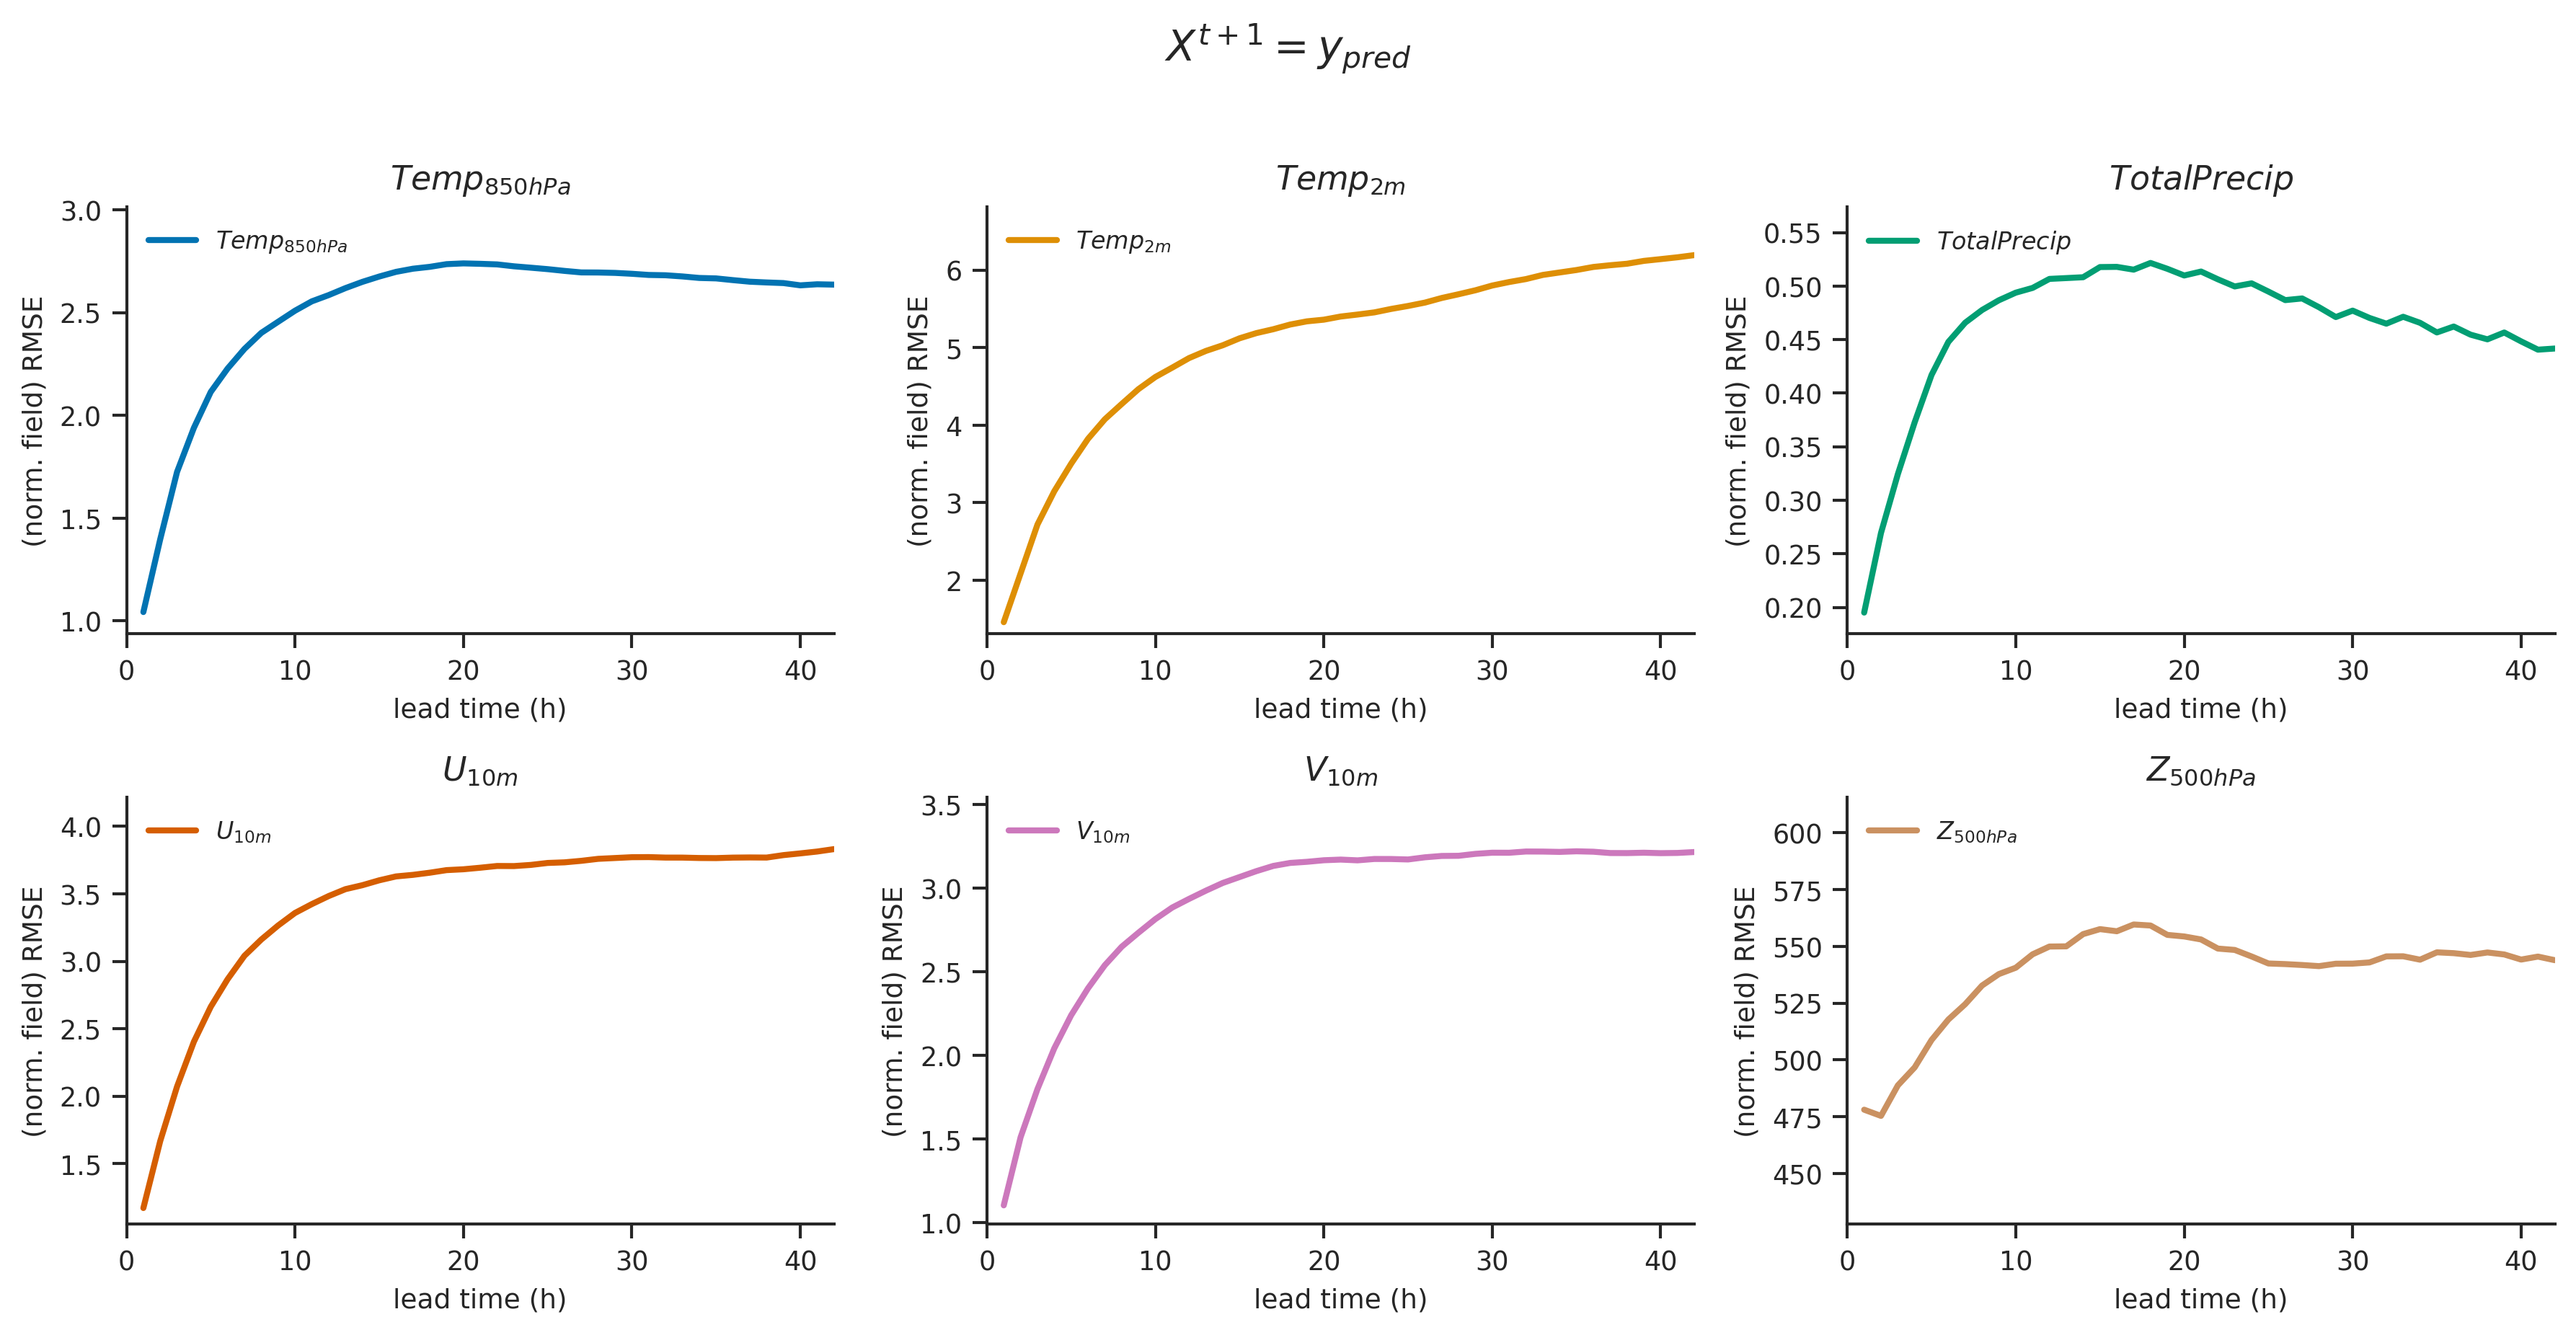

In [9]:
import json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load your JSON data
with open("/data/titan_21var/base_0order_5em4/test_titan/Test_rmse_scores.json", 'r') as file:
    data = json.load(file)

# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Lead times
LTs = np.arange(1, 43, 1)

# Variables, names, and line styles
var = ["aro_t_850hpa", "aro_t2m_2m","aro_tp_0m", "aro_u10_10m", "aro_v10_10m",  "aro_z_500hpa"]
var_name = [r'$Temp_{850hPa}$', r'$Temp_{2m}$',r'$Total Precip$', r'$U_{10m}$', r'$V_{10m}$',  r'$Z_{500hPa}$']
linestyle = ['-.', '--', '-', ':', (0, (3, 1, 1, 1, 1, 1)), (0, (3, 5, 1, 5))]

# Create subplots grid (2 rows, 3 cols → 6 panels, but last one will be empty)
fig, axes = plt.subplots(2, 3, figsize=(12, 6), dpi=300)
axes = axes.flatten()  # Flatten for easy iteration

# Loop through each variable
for k in range(len(var)):
    ax = axes[k]
    ax.plot(LTs, data[var[k]], label=var_name[k],
            color=palette[k], linestyle='-', linewidth=2)

    # Labels
    ax.set_xlabel(r'lead time (h)', fontsize=9)
    ax.set_ylabel(r'(norm. field) RMSE', fontsize=9)
    ax.set_title(var_name[k], fontsize=11, weight='bold')

    # Example: independent axis limits (you can set per variable)
    ax.set_xlim(0, 42)
    # if var[k]=="aro_z_500hpa":
    #     ax.set_ylim(400, np.max(data[var[k]]) * 1.1)
    # elif var[k]=="aro_tp_0m":
    #     ax.set_ylim(0, np.max(data[var[k]]) * 1.1)
    # else:
    #     ax.set_ylim(np.min(data[var[k]]), np.max(data[var[k]]) * 1.1)  # auto-scaled individually
    ax.set_ylim(np.min(data[var[k]])*0.9, np.max(data[var[k]]) * 1.1)

    # Legend inside each subplot
    ax.legend(frameon=False, fontsize=8, loc='upper left')

    sns.despine(ax=ax)

fig.suptitle(
    r'$X^{t+1}=y_{pred}$',
    fontsize=14, weight='bold', y=1.02
)

plt.tight_layout()
plt.show()


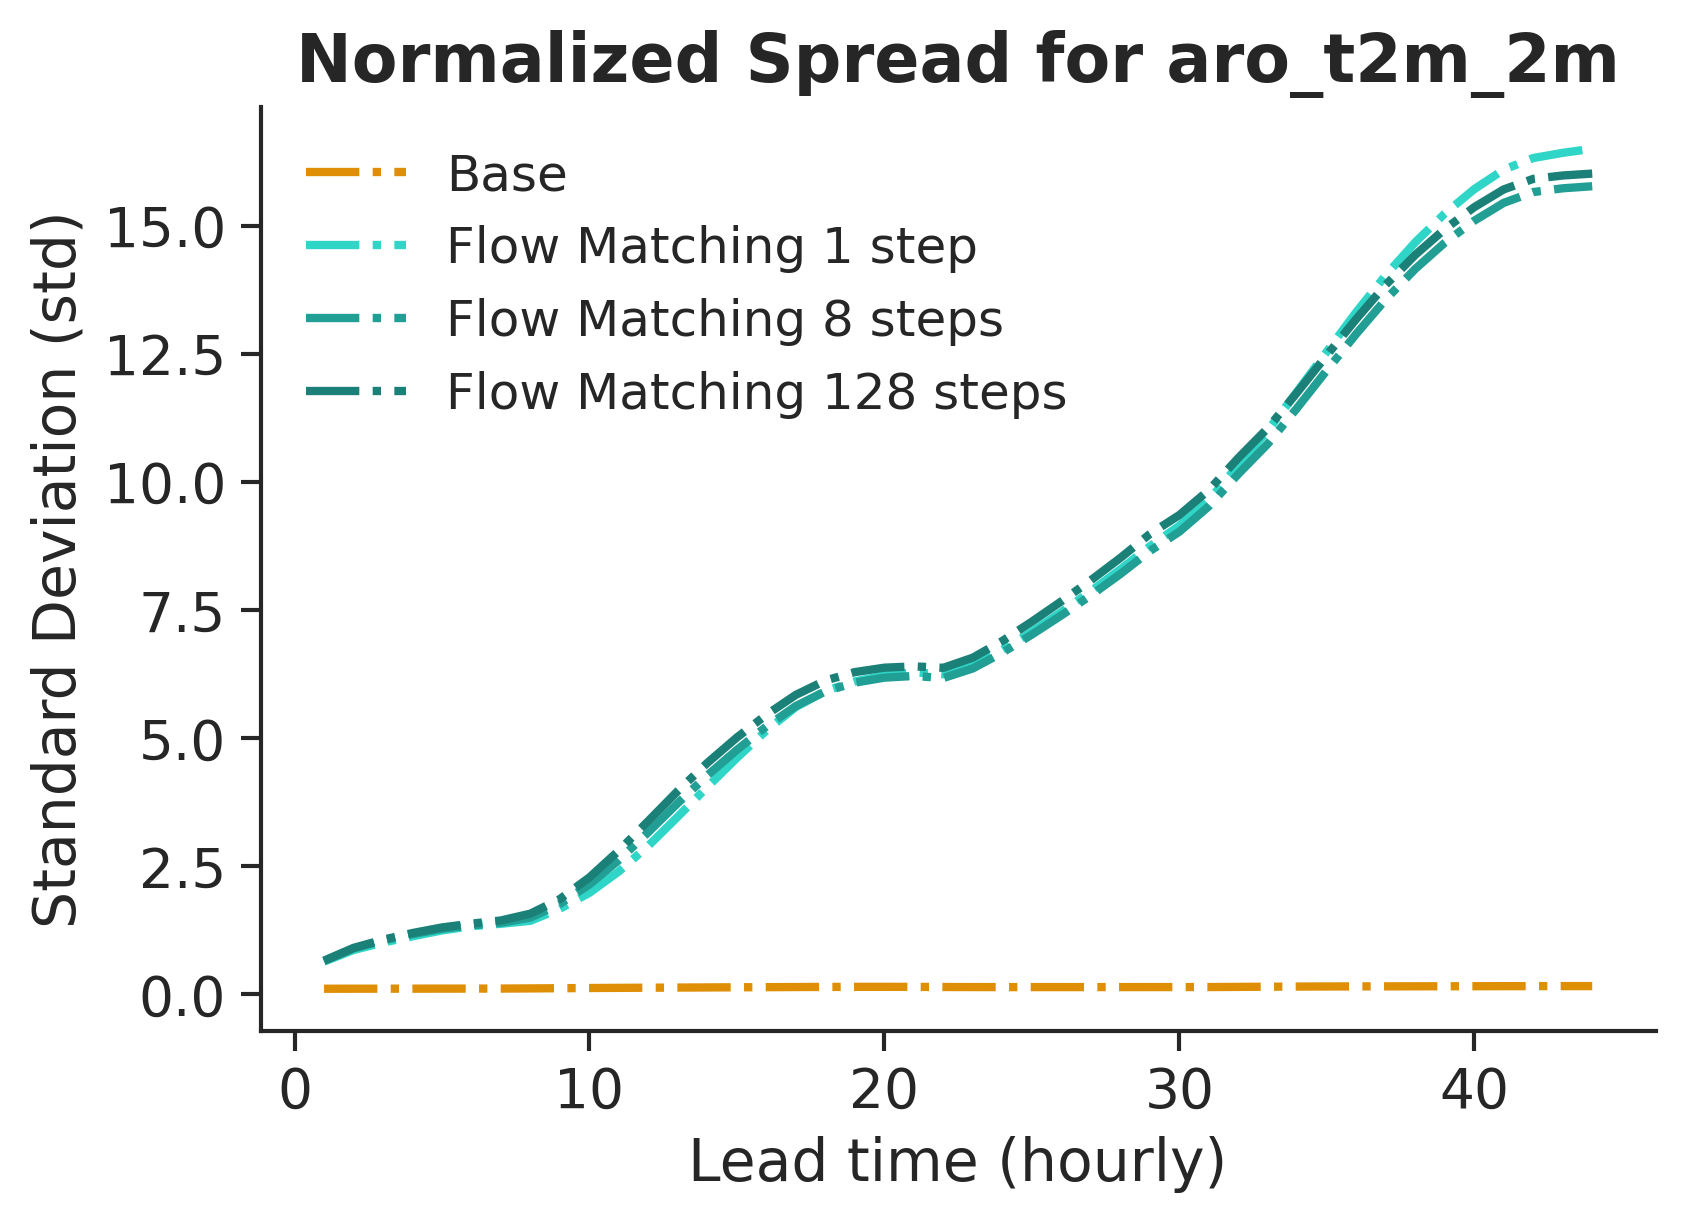

In [ ]:
# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1.5)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Create the figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

LTs = np.arange(1, 45, 1)

# Plot with distinct, publication-quality colors and styles

ax.plot(df_base['step'], df_base['value'], label='Base',
        color=palette[1], linestyle='-.', linewidth=2)
ax.plot(df_forcing['step'], df_forcing['value'], label='Forcing',
        color=palette[2], linestyle='-.', linewidth=2)
ax.plot(df_smooth['step'], df_smooth['value'], label='Smooth',
        color=palette[3], linestyle='-.', linewidth=2)
ax.plot(df_stoEPA['step'], df_stoEPA['value'], label='Stochastic EPA',
        color=palette[4], linestyle='-.', linewidth=2)
ax.plot(LTs, value_1, label='Flow Matching 1 step',
        color="#2fd6c7", linestyle='-.', linewidth=2)
# ax.plot(LTs, value_8, label='Flow Matching 4 steps',
#         color="#229f94", linestyle='-.', linewidth=2)
# ax.plot(LTs, value_128, label='Flow Matching 128 steps',
#         color="#1b8077", linestyle='-.', linewidth=2)

# Labels and title with LaTeX for better typography
ax.set_xlabel(r'Lead time (hourly)', fontsize=14)
ax.set_ylabel(r'RMSE', fontsize=14)
ax.set_title(r'Distance to Poesy members for ' + var, fontsize=16, weight='bold')

# Customize legend
ax.legend(frameon=False, fontsize=12)

# Remove top and right borders
sns.despine()

# Show the plot
plt.show()

## Spread plots per LTs

In [25]:
var = "z_500hpa"

In [26]:
log_dir = "/data/baseARP/test_poesy/Test_std_timestep_pearo_"+var+"_poesy_refacto_EURW1S40_refacto/"
reader = SummaryReader(log_dir)
df_poesy = reader.scalars

log_dir = "/data/baseARP/test_poesy/Test_std_timestep_pearo_"+var+"_preds"
reader = SummaryReader(log_dir)
df_base = reader.scalars

log_dir = "/data/Unetrpp_crps_forcing_ARP/test_poesy/Test_std_timestep_pearo_"+var+"_preds"
reader = SummaryReader(log_dir)
df_forcing = reader.scalars

# log_dir = "/data/Unetrpp_crps_smooth/test_poesy/Test_std_timestep_pearo_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_smooth = reader.scalars

# log_dir = "/data/Unetrpp_crps_stoEPA/test_poesy/Test_std_timestep_pearo_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_stoEPA = reader.scalars

log_dir = "/data/Unetrpp_FM_forcing_ARP_v2/test_poesy/Test_std_timestep_pearo_"+var+"_preds"
reader = SummaryReader(log_dir)
df_FM1 = reader.scalars

# log_dir = "/data/Unetrpp_FM/test_poesy_4steps/Test_std_timestep_pearo_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_FM8 = reader.scalars

# log_dir = "/data/Unetrpp_FM/test_poesy_128steps/Test_std_timestep_pearo_"+var+"_preds"
# reader = SummaryReader(log_dir)
# df_FM128 = reader.scalars

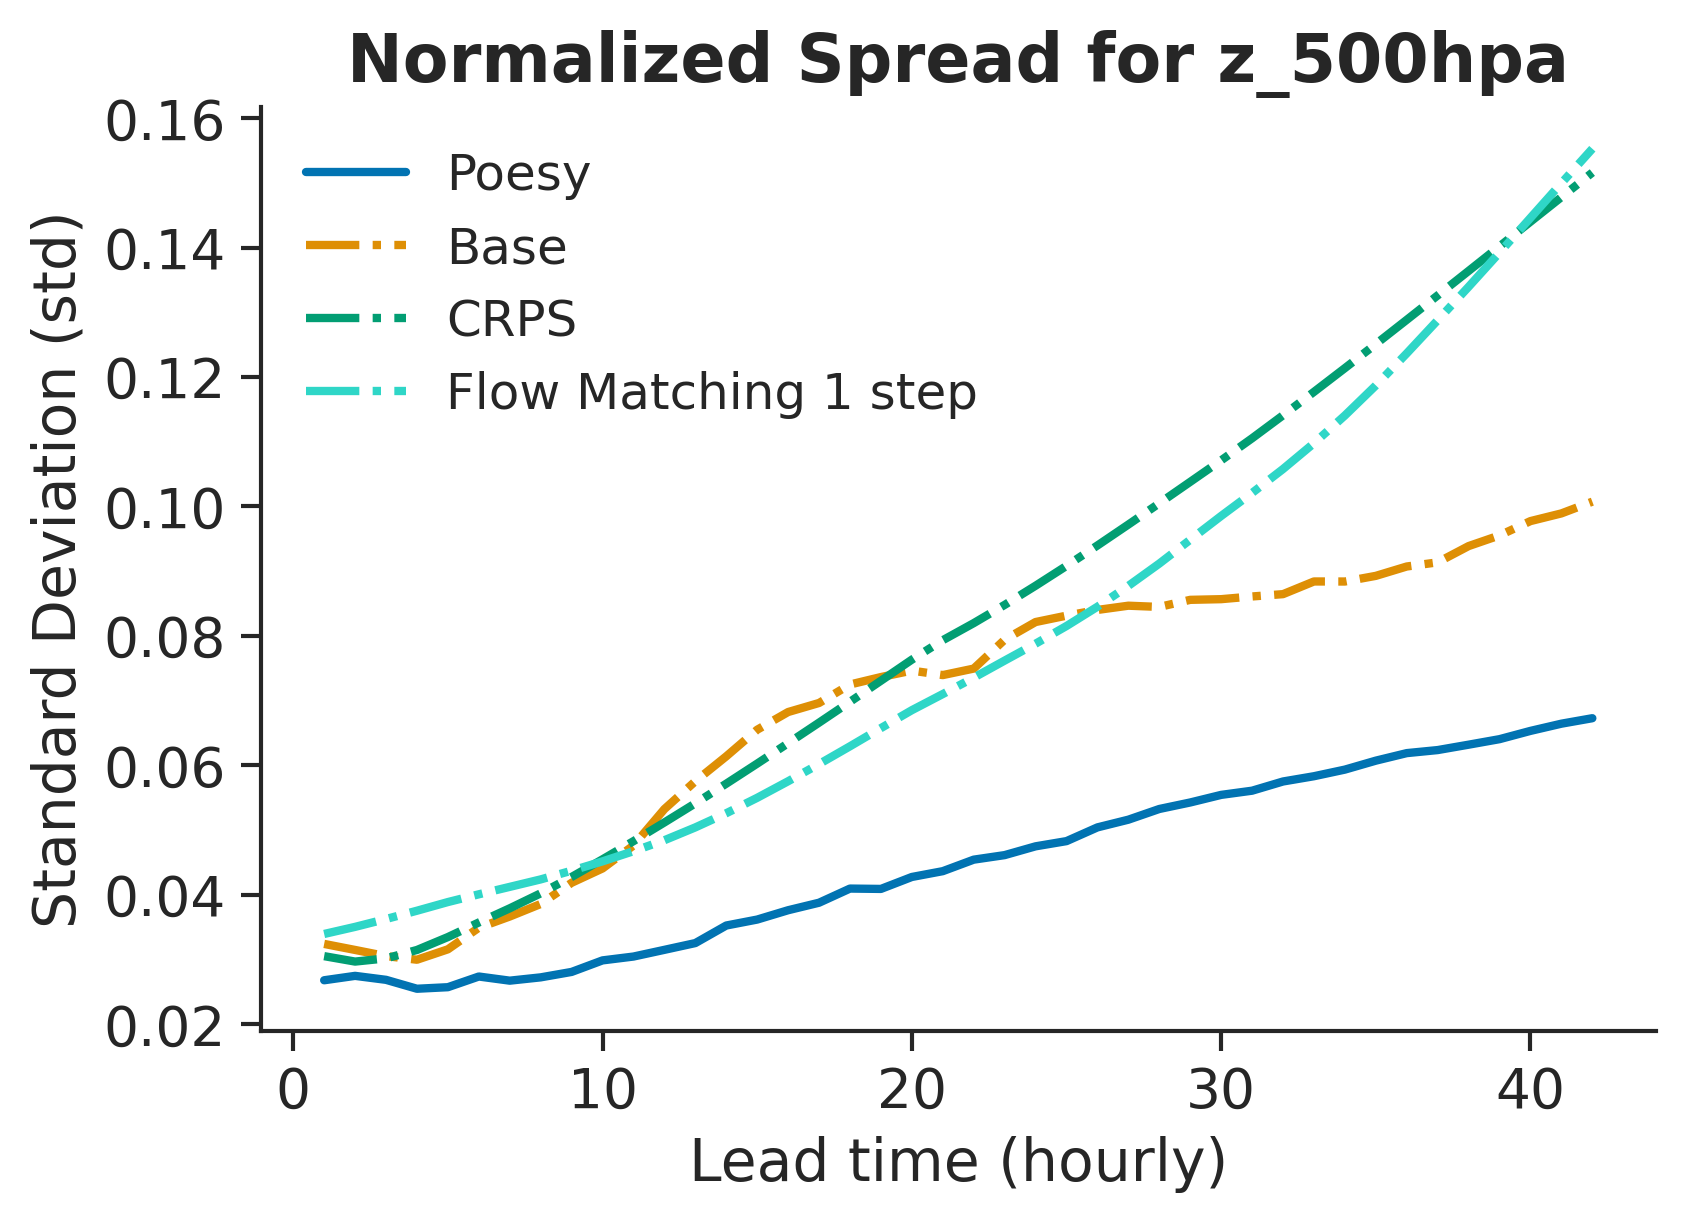

In [27]:
import seaborn as sns
import matplotlib.pyplot as plt

# Set Seaborn style for professional aesthetics
sns.set_context("paper", font_scale=1.5)
sns.set_style("ticks")

# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

# Create the figure
fig, ax = plt.subplots(figsize=(6, 4), dpi=300)

# Plot with distinct, publication-quality colors and styles
ax.plot(df_poesy['step'], df_poesy['value'], label='Poesy',
        color=palette[0], linestyle='-', linewidth=2)
ax.plot(df_base['step'], df_base['value'], label='Base',
        color=palette[1], linestyle='-.', linewidth=2)
ax.plot(df_forcing['step'], df_forcing['value'], label='rse',
        color=palette[2], linestyle='-.', linewidth=2)
# ax.plot(df_smooth['step'], df_smooth['value'], label='Smooth',
#         color=palette[3], linestyle='-.', linewidth=2)
# ax.plot(df_stoEPA['step'], df_stoEPA['value'], label='Stochastic EPA',
#         color=palette[4], linestyle='-.', linewidth=2)
ax.plot(df_FM1['step'], df_FM1['value'], label='Flow Matching 1 step',
        color="#2fd6c7", linestyle='-.', linewidth=2)
# ax.plot(df_FM8['step'], df_FM8['value'], label='Flow Matching 4 steps',
#         color="#229f94", linestyle='-.', linewidth=2)
# ax.plot(df_FM128['step'], df_FM128['value'], label='Flow Matching 128 steps',
#         color="#1b8077", linestyle='-.', linewidth=2)

# Labels and title with LaTeX for better typography
ax.set_xlabel(r'Lead time (hourly)', fontsize=14)
ax.set_ylabel(r'Standard Deviation (std)', fontsize=14)
ax.set_title(r'Normalized Spread for ' + var, fontsize=16, weight='bold')

# Customize legend
ax.legend(frameon=False, fontsize=12)

# Remove top and right borders
sns.despine()

# Save as a high-quality vector image
plt.savefig("normalized_spread_std.pdf", bbox_inches='tight', transparent=True)

# Show the plot
plt.show()


## Spread Skill Plots

In [25]:
var = "pearo_t2m_2m"

In [ ]:
poesy_ssp = np.load(f"/data/base/test_poesy/pepearo_spread_skill_plot_per_param_{var}_LT_0-10.npy")

base_ssp = np.load(f"/data/base/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

forcing_ssp = np.load(f"/data/Unetrpp_rse_8nm_v2/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

smooth_ssp = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

stoEPA_ssp = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

FM_ssp = np.load(f"/data/Unetrpp_FM/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy") 

# FM8_ssp = np.load(f"/data/Unetrpp_FM/test_poesy_4steps/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

# FM128_ssp = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/preds_spread_skill_plot_per_param_{var}_LT_0-10.npy")

In [ ]:
# poesy_ssp = np.load(f"/data/base/test_poesy/pepearo_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# base_ssp = np.load(f"/data/base/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# forcing_ssp = np.load(f"/data/Unetrpp_crps_8nm_v2/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# smooth_ssp = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# stoEPA_ssp = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy")

# FM_ssp = np.load(f"/data/Unetrpp_FM/test_poesy/preds_spread_skill_plot_per_param_{var}_LT_10-20.npy") 

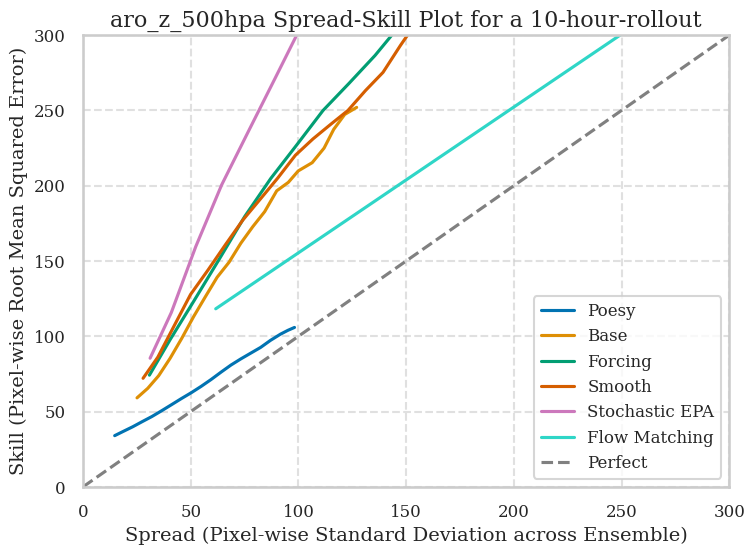

In [ ]:
sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,  # Set to True if LaTeX is installed
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})
plt.figure(figsize=(8, 6))
sns.lineplot(x=poesy_ssp[0], y=poesy_ssp[1], label="Poesy", color=palette[0])
sns.lineplot(x=base_ssp[0], y=base_ssp[1],  label="Base", color=palette[1])
sns.lineplot(x=forcing_ssp[0], y=forcing_ssp[1],  label="Forcing", color=palette[2])
sns.lineplot(x=smooth_ssp[0], y=smooth_ssp[1],  label="Smooth", color=palette[3])
sns.lineplot(x=stoEPA_ssp[0], y=stoEPA_ssp[1],  label="Stochastic EPA", color=palette[4])
sns.lineplot(x=FM_ssp[0], y=FM_ssp[1],  label="Flow Matching", color="#2fd6c7")
# sns.lineplot(x=FM8_ssp[0], y=FM8_ssp[1],  label="Flow Matching 4 steps", color="#229f94")
# sns.lineplot(x=FM128_ssp[0], y=FM128_ssp[1],  label="Flow Matching 128 steps", color="#1b8077")

# Add perfect line y=x
x = np.linspace(0, 300, 100)
y = x
plt.plot(x, y, color="grey", linestyle="--", label="Perfect")

plt.xlabel("Spread (Pixel-wise Standard Deviation across Ensemble)")
plt.ylabel("Skill (Pixel-wise Root Mean Squared Error)")
plt.title(var+" Spread-Skill Plot for a 10-hour-rollout")
plt.grid(True, linestyle="--", alpha=0.6)
plt.xlim(0, 300)
plt.ylim(0, 300)
plt.legend()
plt.tight_layout()
plt.show()


## Spread Error Ratio 

In [45]:
var = "pearo_z_500hpa"

In [46]:
poesy_rse = np.load(f"/data/baseARP/test_poesy/pearo_spread_error_ratio_plot_per_param_{var}.npy")

base_rse = np.load(f"/data/baseARP/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

forcing_rse = np.load(f"/data/Unetrpp_crps_forcing_ARP/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

# smooth_rse = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

# stoEPA_rse = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")

FM_rse = np.load(f"/data/Unetrpp_FM_forcing_ARP_v2/test_poesy/preds_spread_error_ratio_plot_per_param_{var}.npy")
# FM8_rse = np.load(f"/data/Unetrpp_FM/test_poesy_4steps/preds_spread_error_ratio_plot_per_param_{var}.npy")
# FM128_rse = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/preds_spread_error_ratio_plot_per_param_{var}.npy")

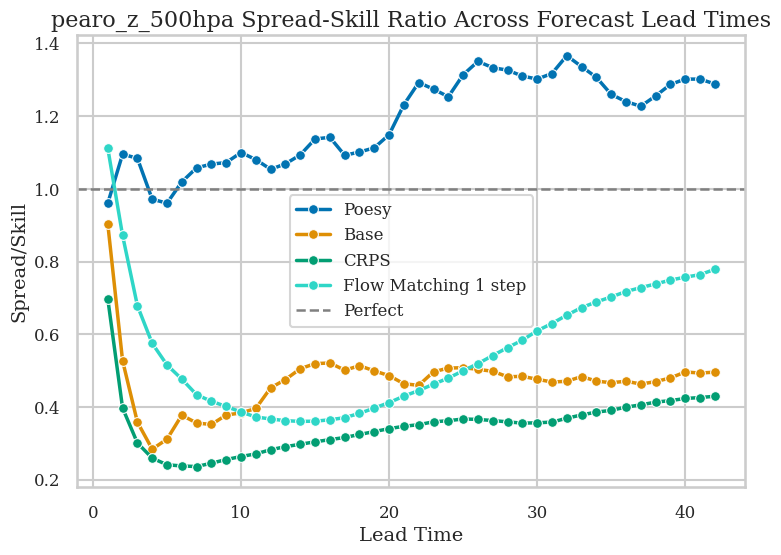

In [47]:
# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,  # Set to True if LaTeX is installed
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

lead_times = np.arange(1, poesy_rse.shape[0] + 1)
plt.figure(figsize=(8, 6))
sns.lineplot(x=lead_times, y=poesy_rse, marker="o", markersize=7, label="Poesy", linewidth=2.5, color=palette[0])
sns.lineplot(x=lead_times, y=base_rse, marker="o", markersize=7, label="Base", linewidth=2.5, color=palette[1])
sns.lineplot(x=lead_times, y=forcing_rse, marker="o", markersize=7, label="CRPS", linewidth=2.5, color=palette[2])
# sns.lineplot(x=lead_times, y=smooth_rse, marker="o", markersize=7, label="Smooth", linewidth=2.5, color=palette[3])
# sns.lineplot(x=lead_times, y=stoEPA_rse, marker="o", markersize=7, label="Stochastic EPA", linewidth=2.5, color=palette[4])
sns.lineplot(x=lead_times, y=FM_rse, marker="o", markersize=7, label="Flow Matching 1 step", linewidth=2.5, color="#2fd6c7")
# sns.lineplot(x=lead_times, y=FM8_rse, marker="o", markersize=7, label="Flow Matching 4 steps", linewidth=2.5, color="#229f94")
# sns.lineplot(x=lead_times, y=FM128_rse, marker="o", markersize=7, label="Flow Matching 128 steps", linewidth=2.5, color="#1b8077")

# Add perfect ratio reference line
plt.axhline(y=1, color="grey", linestyle="--", linewidth=1.8, label="Perfect")

# Labels and title
plt.xlabel("Lead Time")
plt.ylabel("Spread/Skill")
plt.title(f"{var} Spread-Skill Ratio Across Forecast Lead Times")
plt.legend(loc="best", frameon=True)

# Tight layout and publication-ready formatting
plt.tight_layout()
plt.show()

## CRPS

In [13]:
var = "pearo_t2m_2m"

In [15]:
poesy_crps = np.load(f"/data/titan_21var/afcrps_0order_5em4/test_poesy_6var_1rlt/pearo_crps_plot_per_param_{var}.npy")

order0_crps = np.load(f"/data/titan_21var/afcrps_0order_5em4/test_poesy_6var_1rlt/preds_crps_plot_per_param_{var}.npy")

# base_crps = np.load(f"/data/baseARP/test_poesy/preds_crps_plot_per_param_{var}.npy")

# forcing_crps = np.load(f"/data/Unetrpp_crps_forcing_ARP/test_poesy/preds_crps_plot_per_param_{var}.npy")

# # smooth_crps = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/preds_crps_plot_per_param_{var}.npy")

# # stoEPA_crps = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/preds_crps_plot_per_param_{var}.npy")

# FM_crps = np.load(f"/data/Unetrpp_FM_forcing_ARP_v2/test_poesy/preds_crps_plot_per_param_{var}.npy")
# # FM8_crps = np.load(f"/data/Unetrpp_FM/test_poesy_4steps/preds_crps_plot_per_param_{var}.npy")
# # FM128_crps = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/preds_crps_plot_per_param_{var}.npy")

In [ ]:
["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m", "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]

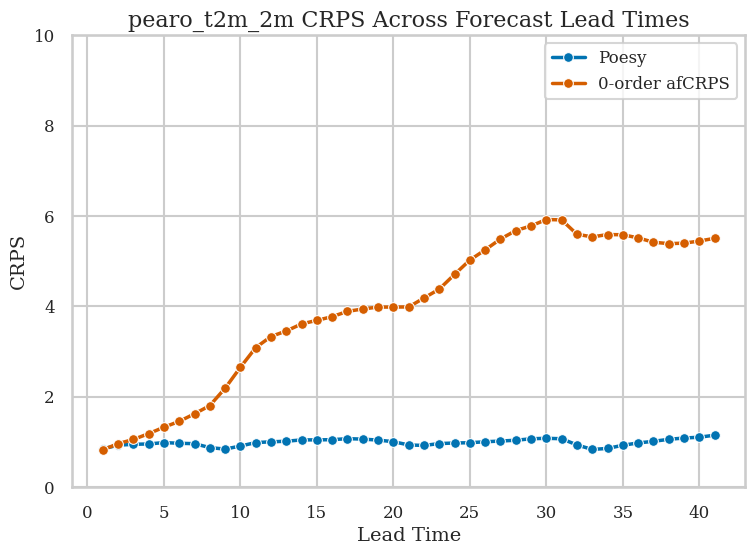

In [17]:
# Use a colorblind-friendly palette
palette = sns.color_palette("colorblind")

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

lead_times = np.arange(1, poesy_crps.shape[0] + 1)
plt.figure(figsize=(8, 6))
sns.lineplot(x=lead_times, y=poesy_crps, marker="o", markersize=7, label="Poesy", linewidth=2.5, color=palette[0])
sns.lineplot(x=lead_times, y=order0_crps, marker="o", markersize=7, label="0-order afCRPS", linewidth=2.5, color=palette[3])
# sns.lineplot(x=lead_times, y=base_crps, marker="o", markersize=7, label="Base", linewidth=2.5, color=palette[1])
# sns.lineplot(x=lead_times, y=forcing_crps, marker="o", markersize=7, label="CRPS", linewidth=2.5, color=palette[2])
# # sns.lineplot(x=lead_times, y=smooth_crps, marker="o", markersize=7, label="Smooth", linewidth=2.5, color=palette[3])
# # sns.lineplot(x=lead_times, y=stoEPA_crps, marker="o", markersize=7, label="Stochastic EPA", linewidth=2.5, color=palette[4])
# sns.lineplot(x=lead_times, y=FM_crps, marker="o", markersize=7, label="Flow Matching 1 step", linewidth=2.5, color="#2fd6c7")
# # sns.lineplot(x=lead_times, y=FM8_crps, marker="o", markersize=7, label="Flow Matching 4 steps", linewidth=2.5, color="#229f94")
# # sns.lineplot(x=lead_times, y=FM128_crps, marker="o", markersize=7, label="Flow Matching 128 steps", linewidth=2.5, color="#1b8077")

# Labels and title
plt.xlabel("Lead Time")
plt.ylabel("CRPS")
plt.ylim(0, 10)
plt.title(f"{var} CRPS Across Forecast Lead Times")
plt.legend(loc="best", frameon=True)
plt.tight_layout()
plt.show()

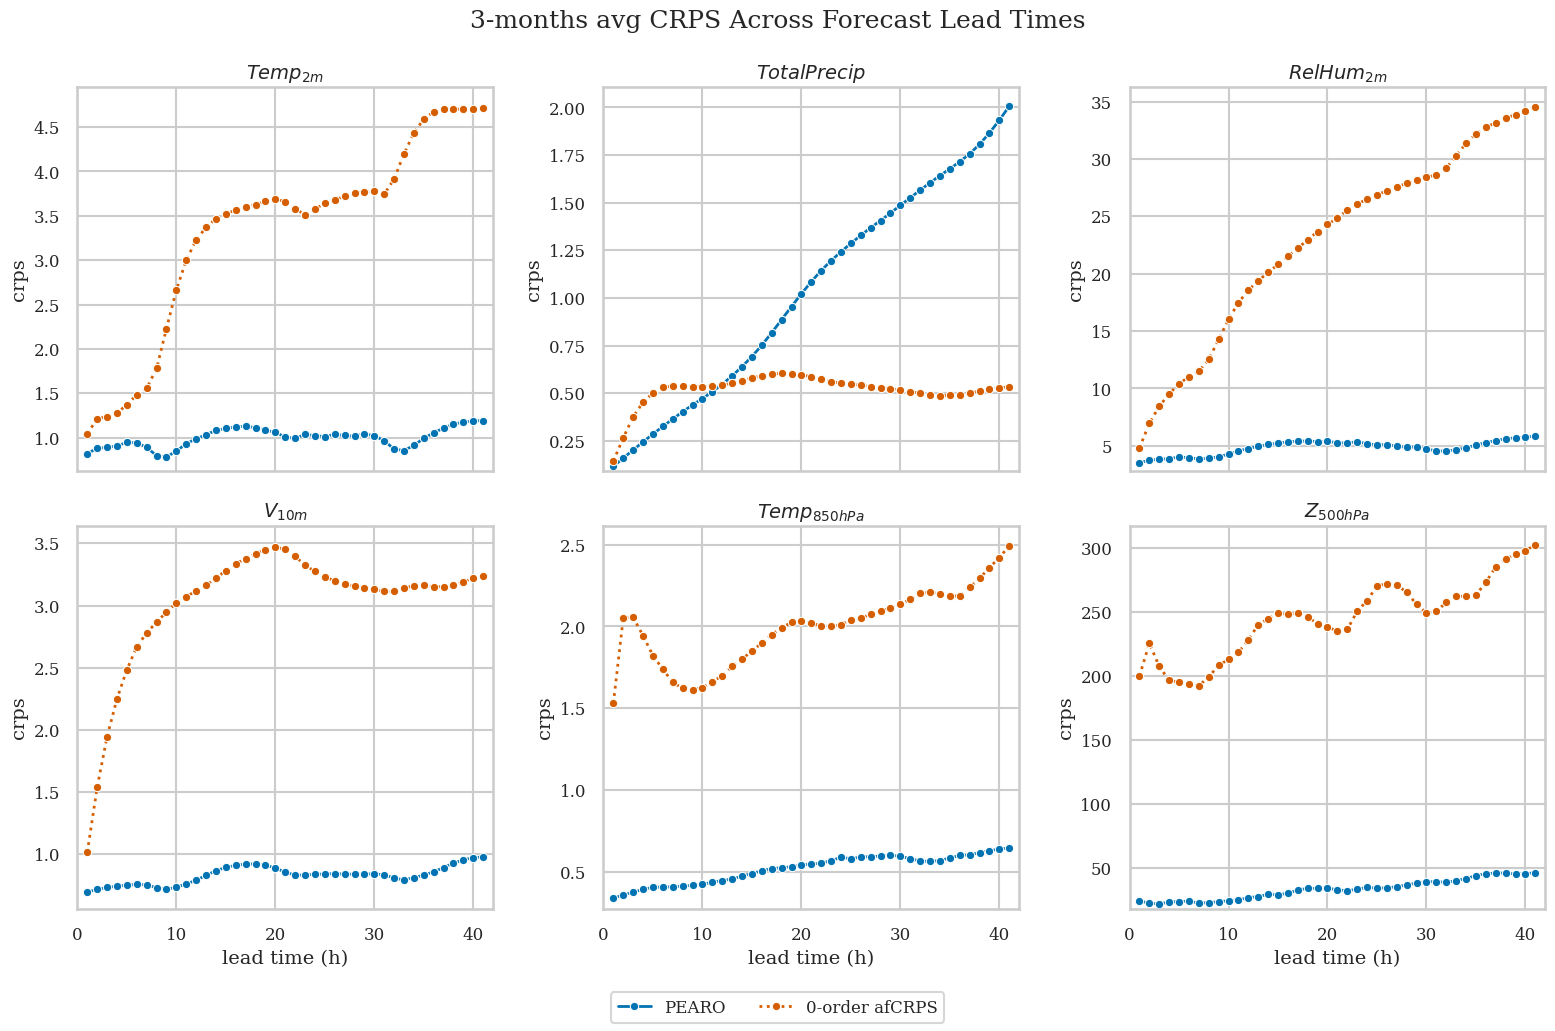

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Colorblind-friendly palette
palette = sns.color_palette("colorblind")

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

# Example variable list
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]
var_name = [r'$Temp_{2m}$', r'$Total Precip$', r'$Rel Hum_{2m}$',
            r'$V_{10m}$', r'$Temp_{850hPa}$', r'$Z_{500hPa}$']

# Example lead times
lead_times = np.arange(1, 42)

# Create 2x3 figure
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=False)

# Collect handles for legend
handles, labels = None, None

for i, var in enumerate(vars):
    ax = axes[i // 3, i % 3]

    poesy_crps = np.load(f"/data/titan_21var/afcrps_0order_5em4/test_poesy_6var/pearo_crps_plot_per_param_{var}.npy")
    order0_crps = np.load(f"/data/titan_21var/afcrps_0order_5em4/test_poesy_6var/preds_crps_plot_per_param_{var}.npy")

    sns.lineplot(x=lead_times, y=poesy_crps,
                 label="PEARO", linewidth=2, color=palette[0], ax=ax, linestyle='-', marker="o", markersize=6)
    sns.lineplot(x=lead_times, y=order0_crps,
                 label="0-order afCRPS", linewidth=2, color=palette[3], ax=ax, linestyle=':', marker="o", markersize=6)
    
    ax.set_xlabel("lead time (h)")
    ax.set_ylabel("crps")
    ax.set_xlim(0, 42)
    ax.set_ylim(np.min((poesy_crps, order0_crps)) * 0.8, np.max((poesy_crps, order0_crps)) * 1.05)
    ax.set_title(var_name[i], fontsize=14, weight='bold')
    ax.legend(loc="best", frameon=True)
    # Capture legend handles once
    if handles is None and labels is None:
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()  # remove subplot legends

plt.tight_layout()
# Add global title
fig.suptitle("3-months avg CRPS Across Forecast Lead Times", fontsize=18, y=1.02)
# Add global legend at bottom
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=True, fontsize=12)
plt.subplots_adjust(bottom=0.12) 
plt.show()


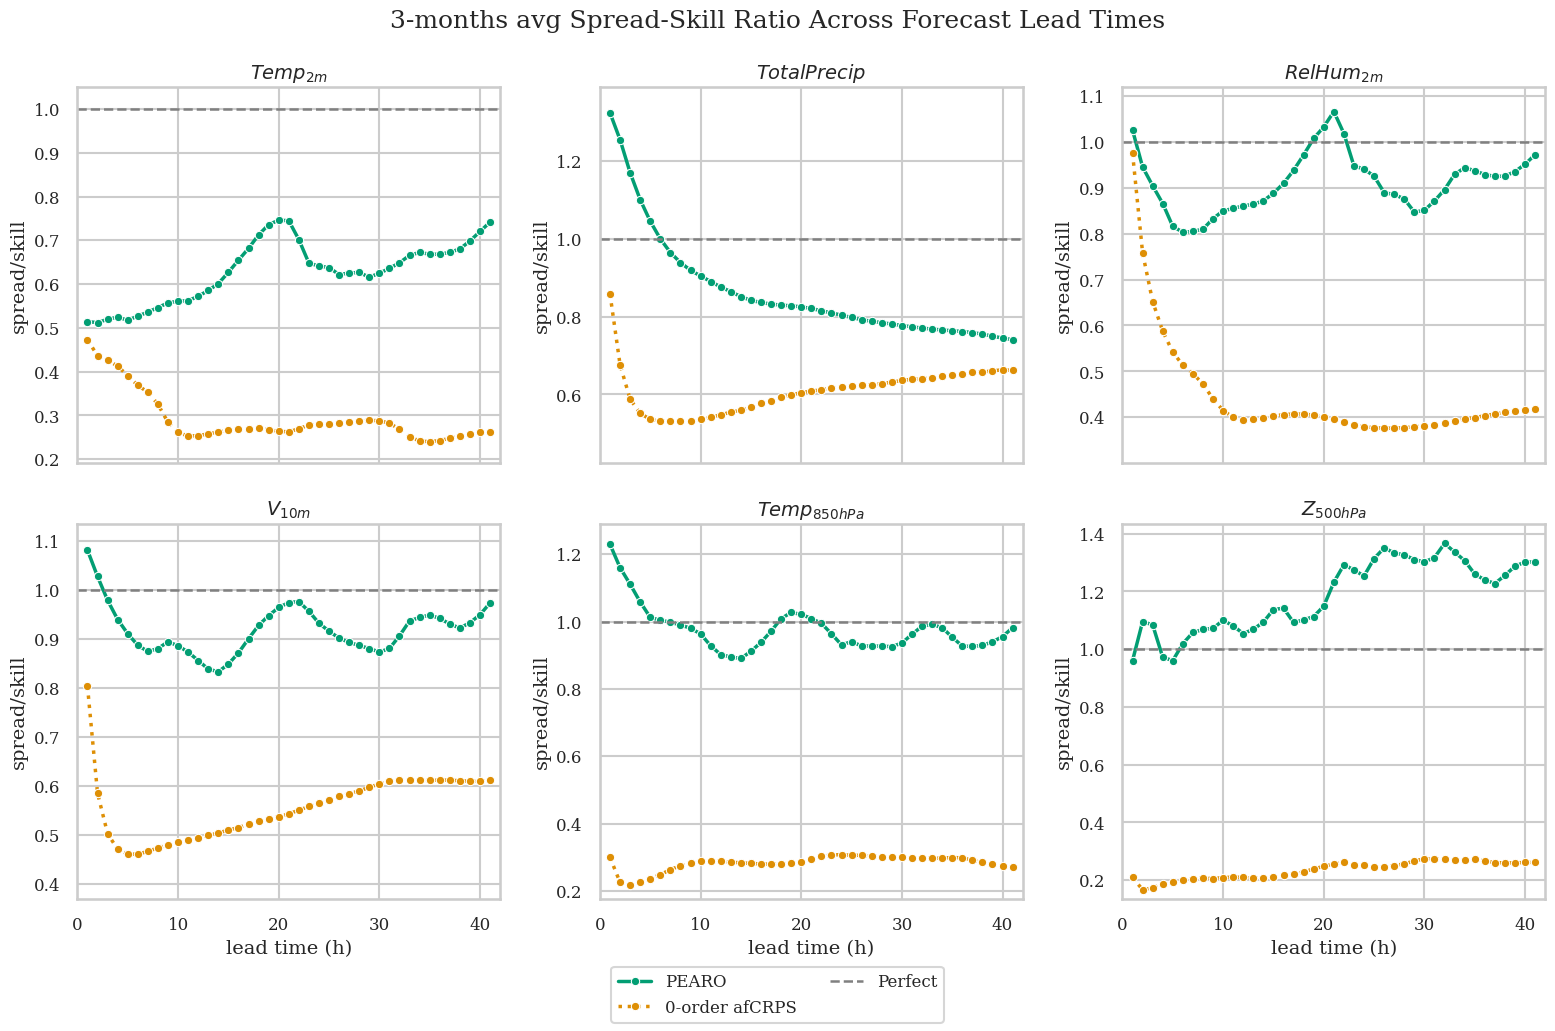

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Colorblind-friendly palette
palette = sns.color_palette("colorblind")

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

# Example variable list
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]
var_name = [r'$Temp_{2m}$', r'$Total Precip$', r'$Rel Hum_{2m}$',
            r'$V_{10m}$', r'$Temp_{850hPa}$', r'$Z_{500hPa}$']

# Example lead times
lead_times = np.arange(1, 42)

# Create 2x3 figure
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=False)

# Collect handles for legend
handles, labels = None, None

for i, var in enumerate(vars):
    ax = axes[i // 3, i % 3]

    poesy_rse = np.load(f"/data/titan_21var/afcrps_0order_5em4/test_poesy_6var/pearo_spread_error_ratio_plot_per_param_{var}.npy")
    order0_rse = np.load(f"/data/titan_21var/afcrps_0order_5em4/test_poesy_6var/preds_spread_error_ratio_plot_per_param_{var}.npy")

    sns.lineplot(x=lead_times, y=poesy_rse,
                 label="PEARO", linewidth=2.5, color=palette[2], ax=ax, linestyle='-', marker="o", markersize=6)
    sns.lineplot(x=lead_times, y=order0_rse,
                 label="0-order afCRPS", linewidth=2.5, color=palette[1], ax=ax, linestyle=':', marker="o", markersize=6)
    sns.lineplot(x=np.arange(0, poesy_rse.shape[0] + 2), y=np.ones(poesy_rse.shape[0] + 2),
                 label="Perfect", linewidth=1.8, color="grey", ax=ax, linestyle='--')
    
    ax.set_xlabel("lead time (h)")
    ax.set_ylabel("spread/skill")
    ax.set_ylim(np.min((poesy_rse, order0_rse)) * 0.8, np.max((poesy_rse, order0_rse, np.ones(poesy_rse.shape[0]))) * 1.05)
    ax.set_xlim(0, 42)
    ax.set_title(var_name[i], fontsize=14, weight='bold')
    ax.legend(loc="best", frameon=True)
    # Capture legend handles once
    if handles is None and labels is None:
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()  # remove subplot legends

plt.tight_layout()
# Add global title
fig.suptitle("3-months avg Spread-Skill Ratio Across Forecast Lead Times", fontsize=18, y=1.02)
# Add global legend at bottom
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=True, fontsize=12)
plt.subplots_adjust(bottom=0.13) 
plt.show()

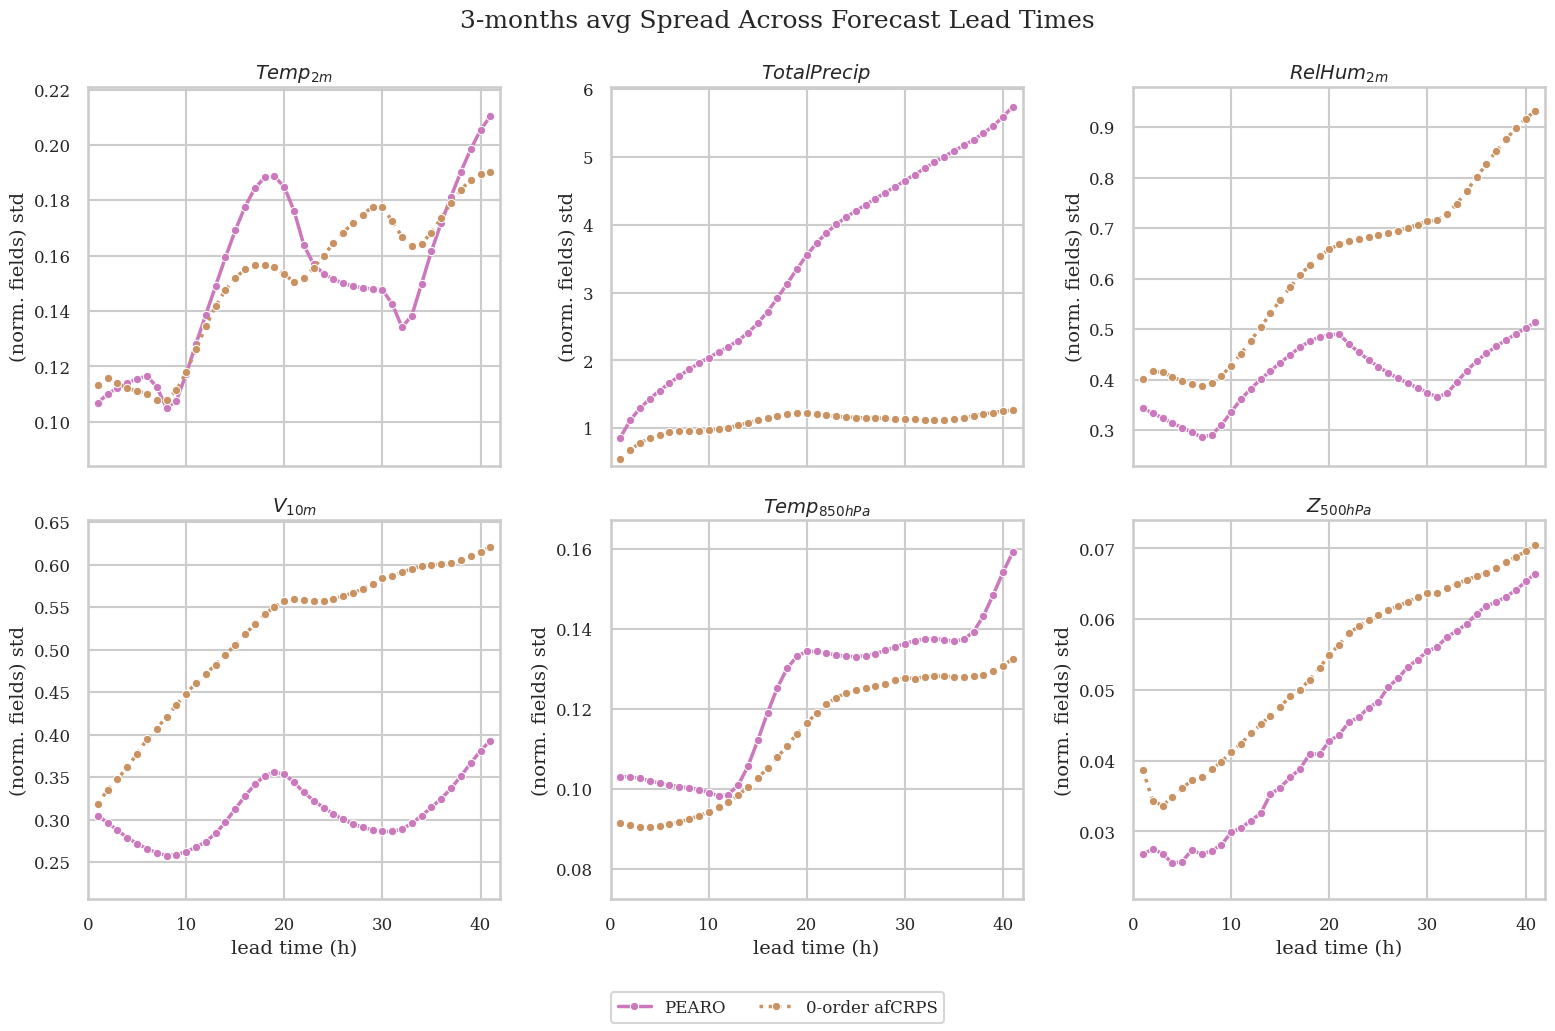

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Colorblind-friendly palette
palette = sns.color_palette("colorblind")

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

# Example variable list
vars = ["pearo_t2m_2m", "pearo_tp_0m", "pearo_r2_2m",
        "pearo_v10_10m", "pearo_t_850hpa", "pearo_z_500hpa"]
var_name = [r'$Temp_{2m}$', r'$Total Precip$', r'$Rel Hum_{2m}$',
            r'$V_{10m}$', r'$Temp_{850hPa}$', r'$Z_{500hPa}$']

# Example lead times
lead_times = np.arange(1, 42)

# Create 2x3 figure
fig, axes = plt.subplots(2, 3, figsize=(16, 10), sharex=True, sharey=False)

# Collect handles for legend
handles, labels = None, None

for i, var in enumerate(vars):
    ax = axes[i // 3, i % 3]
    
    log_dir = "/data/titan_21var/afcrps_0order_5em4/test_poesy_6var/Test_std_timestep_"+var+"_poesy_refacto_EURW1S40_refacto/"
    reader = SummaryReader(log_dir)
    poesy_std = reader.scalars
    log_dir = "/data/titan_21var/afcrps_0order_5em4/test_poesy_6var/Test_std_timestep_"+var+"_preds"
    reader = SummaryReader(log_dir)
    order0_std = reader.scalars

    sns.lineplot(x=lead_times, y=poesy_std['value'],
                 label="PEARO", linewidth=2.5, color=palette[4], ax=ax, linestyle='-', marker="o", markersize=6)
    sns.lineplot(x=lead_times, y=order0_std['value'],
                 label="0-order afCRPS", linewidth=2.5, color=palette[5], ax=ax, linestyle=':', marker="o", markersize=6)
    
    ax.set_xlabel("lead time (h)")
    ax.set_ylabel("(norm. fields) std")
    ax.set_ylim(np.min((poesy_std['value'], order0_std['value'])) * 0.8, np.max((poesy_std['value'], order0_std['value'])) * 1.05)
    ax.set_xlim(0, 42)
    ax.set_title(var_name[i], fontsize=14, weight='bold')
    ax.legend(loc="best", frameon=True)
    # Capture legend handles once
    if handles is None and labels is None:
        handles, labels = ax.get_legend_handles_labels()
    ax.get_legend().remove()  # remove subplot legends

plt.tight_layout()
# Add global title
fig.suptitle("3-months avg Spread Across Forecast Lead Times", fontsize=18, y=1.02)
# Add global legend at bottom
fig.legend(handles, labels, loc="lower center", ncol=2, frameon=True, fontsize=12)
plt.subplots_adjust(bottom=0.13) 
plt.show()

## PSD

In [32]:
var = "z_500hpa"

In [33]:
poesy_psd = np.load(f"/data/baseARP/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")

base_psd = np.load(f"/data/baseARP/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")

# forcing_crps = np.load(f"/data/Unetrpp_crps_forcing_ARP/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")

# smooth_crps = np.load(f"/data/Unetrpp_crps_smooth/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")

# stoEPA_crps = np.load(f"/data/Unetrpp_crps_stoEPA/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")

FM_psd = np.load(f"/data/Unetrpp_FM_forcing_ARP_v2/test_poesy/test_mean_psd_k_pearo_{var}_24.npy")
# FM8_crps = np.load(f"/data/Unetrpp_FM/test_poesy_4steps/test_mean_psd_k_pearo_{var}_24.npy")
# FM128_crps = np.load(f"/data/Unetrpp_FM/test_poesy_128steps/test_mean_psd_k_pearo_{var}_24.npy")

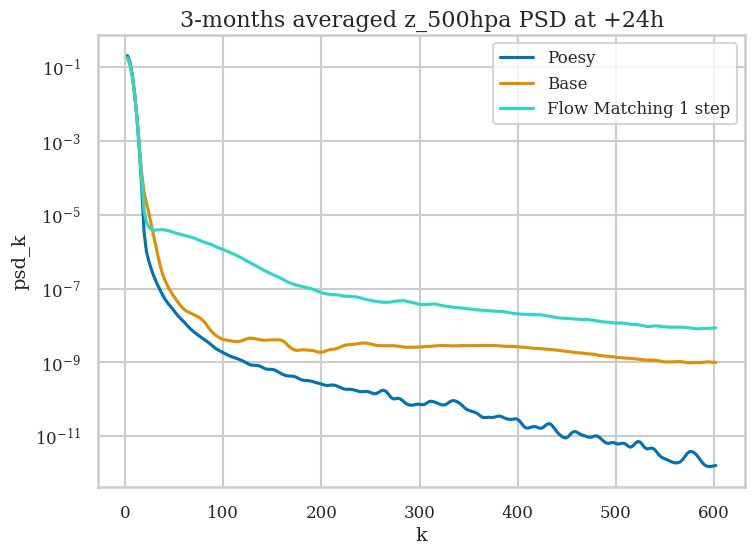

In [34]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d

sns.set(style="whitegrid", context="talk", font_scale=1.2)
plt.rcParams.update({
    "text.usetex": False,
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12
})

palette = sns.color_palette("colorblind")

# Apply Gaussian smoothing
sigma = 1.5  # Controls the smoothing level (higher = smoother)

poesy_smoothed = gaussian_filter1d(poesy_psd[2], sigma)
base_smoothed = gaussian_filter1d(base_psd[1], sigma)
fm_smoothed = gaussian_filter1d(FM_psd[1], sigma)

plt.figure(figsize=(8, 6))
sns.lineplot(x=poesy_psd[0], y=poesy_smoothed, label="Poesy",  color=palette[0])
sns.lineplot(x=poesy_psd[0], y=base_smoothed, label="Base",  color=palette[1])
sns.lineplot(x=FM_psd[0], y=fm_smoothed, label="Flow Matching 1 step",  color="#2fd6c7")

plt.xlabel("k")
plt.ylabel("psd_k")
plt.yscale("log")
plt.title(f"3-months averaged {var} PSD at +24h")
plt.legend(loc="best", frameon=True)
plt.tight_layout()
plt.show()
